Checking whether the MMP and caspase models can predict clinical DILI by themselves.

No model is trained here. I take the assay models' predicted probabilities for the
222 drugs in Held-223 and compare them against the true DILI labels.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

RESULTS = 'DILI_assay_link/results'

# Assay model predictions for every DILI compound, written by build_invitro_features.py.
# These are out-of-bag: if a compound is also in the assay dataset, its score comes only
# from the repeats where it was held out of training. 76% of MMP and 69% of caspase
# compounds are also DILI compounds, so without this the scores would be memorised labels.
feat = pd.read_csv(f'{RESULTS}/invitro_features.csv')
print('compounds with assay scores:', len(feat))
feat.head()

compounds with assay scores: 13241


,InChIKey,TOXICITY,dili_set,mmp_prob,mmp_n_oob_repeats,caspase_prob,caspase_n_oob_repeats
0,LPQZKKCYTLCDGQ-UHFFFAOYSA-N,0,Held-223,0.087240,21,0.045532,21
1,LPYXWGMUVRGUOY-UHFFFAOYSA-N,0,Held-223,0.246211,21,0.036590,21
2,MAGFQRLKWCCTQJ-UHFFFAOYSA-N,0,Held-223,0.122462,21,0.004569,21
3,JAUORDHNHDCTAS-UHFFFAOYSA-N,0,Held-223,0.862241,21,0.436400,21
4,JLYXXMFPNIAWKQ-UHFFFAOYSA-N,0,Held-223,0.323272,21,0.010286,21


In [2]:
# Which model families went into these scores? Read from the saved prediction files.
for assay in ['mmp', 'caspase']:
    d = f'{RESULTS}/{assay}/probs'
    fams = sorted({f.split('_r')[0] for f in os.listdir(d) if f.endswith('_dili.npy')})
    print(f'{assay:8s} {", ".join(fams)}  ({len(fams)} families)')

# Only RF and XGBoost were trained for this, not the full 10-family consensus.

mmp      RF, XGB  (2 families)
caspase  RF, XGB  (2 families)


In [3]:
# Keep only Held-223, the fixed DILI test set.
h = feat[feat.dili_set == 'Held-223'].dropna(subset=['mmp_prob', 'caspase_prob']).copy()
y = h.TOXICITY.values.astype(int)

print(f'Held-223: {len(h)} drugs, {y.sum()} hepatotoxic ({100*y.mean():.1f}%), {(y==0).sum()} not')
h[['InChIKey', 'TOXICITY', 'mmp_prob', 'caspase_prob']].head()

Held-223: 222 drugs, 155 hepatotoxic (69.8%), 67 not


,InChIKey,TOXICITY,mmp_prob,caspase_prob
0,LPQZKKCYTLCDGQ-UHFFFAOYSA-N,0,0.087240,0.045532
1,LPYXWGMUVRGUOY-UHFFFAOYSA-N,0,0.246211,0.036590
2,MAGFQRLKWCCTQJ-UHFFFAOYSA-N,0,0.122462,0.004569
3,JAUORDHNHDCTAS-UHFFFAOYSA-N,0,0.862241,0.436400
4,JLYXXMFPNIAWKQ-UHFFFAOYSA-N,0,0.323272,0.010286


First just compare the average score in each group, before computing any metric.

In [4]:
g = h.groupby('TOXICITY')[['mmp_prob', 'caspase_prob']].agg(['mean', 'median', 'std']).round(3)
g.index = ['not hepatotoxic', 'hepatotoxic']
display(g)

for c in ['mmp_prob', 'caspase_prob']:
    print(f'{c:13s} gap between the two groups = {h.loc[y==1, c].mean() - h.loc[y==0, c].mean():+.4f}')

mmp_prob               caspase_prob              
                    mean median    std         mean median    std
not hepatotoxic    0.284  0.184  0.263        0.193  0.095  0.217
hepatotoxic        0.347  0.268  0.259        0.211  0.148  0.211

mmp_prob      gap between the two groups = +0.0629
caspase_prob  gap between the two groups = +0.0176


The hepatotoxic drugs do score a little higher, which is the right direction,
but the two distributions sit almost on top of each other.

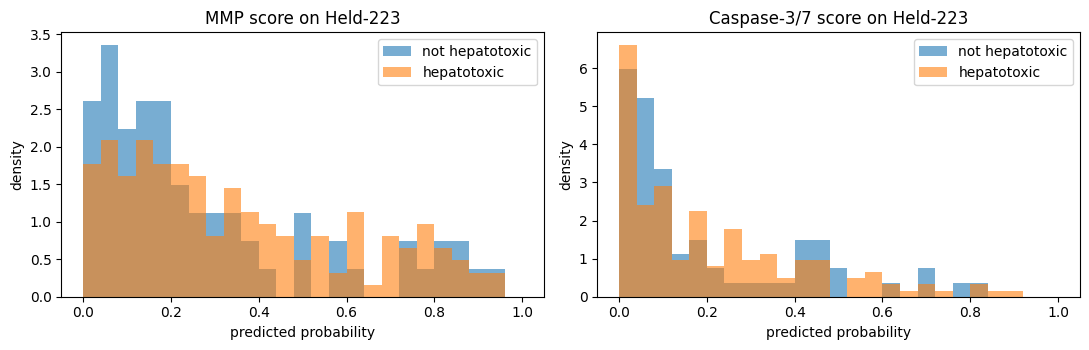

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, c, name in zip(axes, ['mmp_prob', 'caspase_prob'], ['MMP', 'Caspase-3/7']):
    bins = np.linspace(0, 1, 26)
    ax.hist(h.loc[y == 0, c], bins=bins, alpha=.6, density=True, label='not hepatotoxic')
    ax.hist(h.loc[y == 1, c], bins=bins, alpha=.6, density=True, label='hepatotoxic')
    ax.set_title(f'{name} score on Held-223')
    ax.set_xlabel('predicted probability')
    ax.set_ylabel('density')
    ax.legend()
plt.tight_layout()
plt.show()

Now the actual numbers, with a bootstrap confidence interval so we can see whether
anything is better than guessing.

A note on PR-AUC: 69.8% of Held-223 is hepatotoxic, so always answering "toxic"
already gives 0.698. ROC-AUC is the fair comparison and its baseline is 0.5.

In [6]:
def boot_ci(y, p, n=2000, seed=0):
    """95% confidence interval for ROC-AUC, by resampling the drugs."""
    rng = np.random.RandomState(seed)
    v = []
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            v.append(roc_auc_score(y[i], p[i]))
    return np.percentile(v, 2.5), np.percentile(v, 97.5)


# The two assays on their own, plus the two obvious ways of combining them.
h['mean_of_both'] = (h.mmp_prob + h.caspase_prob) / 2
h['max_of_both'] = h[['mmp_prob', 'caspase_prob']].max(axis=1)

rows = []
for c in ['mmp_prob', 'caspase_prob', 'mean_of_both', 'max_of_both']:
    p = h[c].values
    lo, hi = boot_ci(y, p)
    rows.append({'predictor': c,
                 'ROC-AUC': round(roc_auc_score(y, p), 3),
                 'CI_low': round(lo, 3),
                 'CI_high': round(hi, 3),
                 'no_better_than_guessing': lo <= 0.5,
                 'PR-AUC': round(average_precision_score(y, p), 3),
                 'mean_not_toxic': round(p[y == 0].mean(), 3),
                 'mean_toxic': round(p[y == 1].mean(), 3),
                 'gap': round(p[y == 1].mean() - p[y == 0].mean(), 3)})

rows.append({'predictor': 'guessing', 'ROC-AUC': 0.5, 'CI_low': None, 'CI_high': None,
             'no_better_than_guessing': True, 'PR-AUC': round(y.mean(), 3),
             'mean_not_toxic': None, 'mean_toxic': None, 'gap': None})

res = pd.DataFrame(rows)
res.to_csv(f'{RESULTS}/assay_as_dili_predictor.csv', index=False)
res

,predictor,ROC-AUC,CI_low,CI_high,no_better_than_guessing,PR-AUC,mean_not_toxic,mean_toxic,gap
0,mmp_prob,0.584,0.504,0.663,False,0.735,0.284,0.347,0.063
1,caspase_prob,0.537,0.451,0.622,True,0.722,0.193,0.211,0.018
2,mean_of_both,0.573,0.489,0.653,True,0.731,0.239,0.279,0.040
3,max_of_both,0.581,0.496,0.661,True,0.733,0.319,0.385,0.065
4,guessing,0.500,NaN,NaN,True,0.698,NaN,NaN,NaN


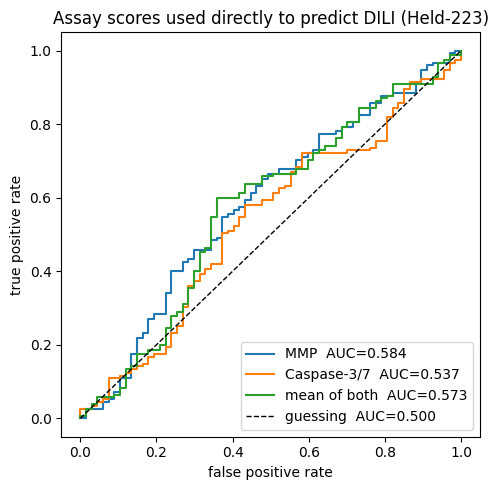

In [7]:
plt.figure(figsize=(5, 5))
for c, name in [('mmp_prob', 'MMP'), ('caspase_prob', 'Caspase-3/7'), ('mean_of_both', 'mean of both')]:
    fpr, tpr, _ = roc_curve(y, h[c])
    plt.plot(fpr, tpr, label=f'{name}  AUC={roc_auc_score(y, h[c]):.3f}')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='guessing  AUC=0.500')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title('Assay scores used directly to predict DILI (Held-223)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

The assay scores do not predict clinical DILI on their own.

MMP gets 0.584 and caspase 0.537, against 0.5 for guessing. The caspase interval
includes 0.5, so it is no better than chance. Combining the two does not help.

The reason is the gap shown earlier: hepatotoxic drugs average 0.347 on MMP and
non-hepatotoxic drugs 0.284. That difference is far too small to separate them.

This makes sense mechanistically. Clinical liver injury also depends on metabolism,
immune response, dose and exposure, and a single cell-line assay does not capture
any of that.

One thing to note: these scores come from RF and XGBoost only, not the full
consensus. Adding XGBoost to RF did not improve the MMP result, so training the
remaining families is unlikely to change the conclusion.